# 02 · Klassische Modelle

Rollierender Backtest: 45 Ursprünge im Abstand von 8 Tagen über das letzte Jahr, Horizont 24 h und 7 Tage. Erzeugt mit `python -m src.backtest`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.report import COLORS, MODELS, INK, MUTED, BLUES, DAYS
from src.backtest import RESULTS

/Users/p.schmidt-petter/Desktop/dev/dev/pedestrian_traffic_forecast/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
fc = pd.read_parquet(RESULTS / 'forecasts.parquet')
fc['model'] = fc['model'].astype(str)
metrics = pd.read_parquet(RESULTS / 'metrics.parquet')
classic = ['SeasonalNaive', 'MSTL-ETS', 'Prophet', 'LightGBM']
metrics[metrics.model.isin(classic)].groupby(['horizon', 'model'])[['MASE', 'sMAPE', 'Coverage80']].mean().round(3)

MASE   sMAPE  Coverage80
horizon model                                   
24      LightGBM       0.711  16.606      70.468
        MSTL-ETS       1.233  23.021      86.269
        Prophet        1.098  23.308      83.252
        SeasonalNaive  1.016  24.495      87.673
168     LightGBM       0.769  18.790      69.168
        MSTL-ETS       1.303  26.472      96.402
        Prophet        1.019  22.964      83.734
        SeasonalNaive  1.012  24.587      87.222

## Verteilung der Fensterfehler

Der Mittelwert versteckt, wie oft ein Modell danebenliegt. Ausreißerwochen (Feiertage, Großevents) dominieren die Rangfolge.

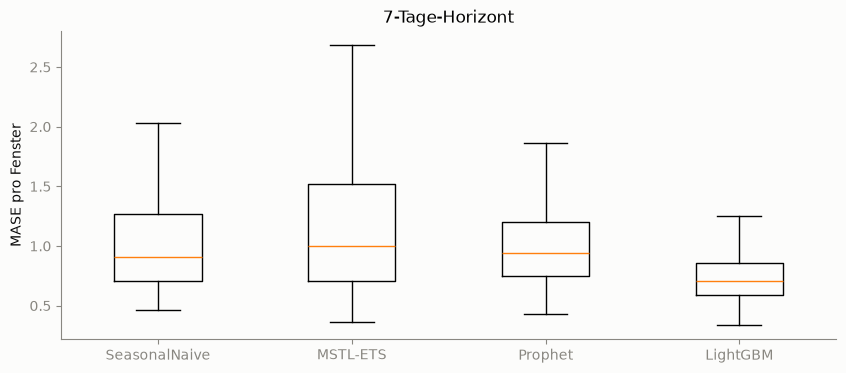

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
d = metrics[(metrics.horizon == 168) & metrics.model.isin(classic)]
ax.boxplot([d[d.model == m].MASE for m in classic], showfliers=False)
ax.set_xticks(range(1, len(classic) + 1), classic)
ax.set(ylabel='MASE pro Fenster', title='7-Tage-Horizont');

## LightGBM: was das globale Modell nutzt

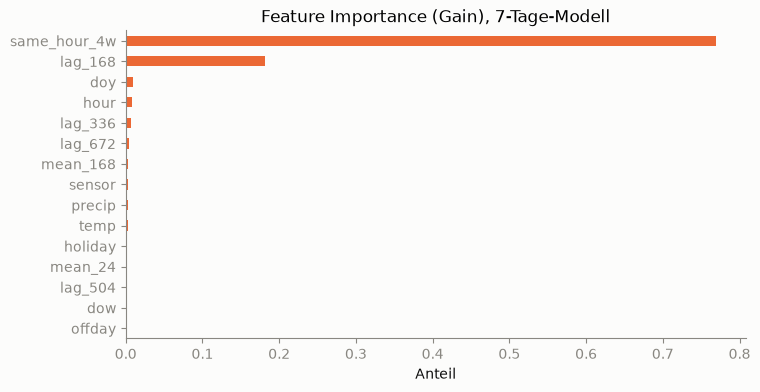

In [4]:
import lightgbm as lgb
import numpy as np
from src.features import build_panel
from src.models import lag_features, LGB_PARAMS, NUM_ROUNDS

panel = build_panel()
df = panel.assign(y=np.log1p(panel.y), sensor=panel.unique_id.astype('category'))
df, lag_cols = lag_features(df, 168)
cols = ['sensor', 'hour', 'dow', 'doy', 'holiday', 'offday', 'temp', 'precip'] + lag_cols
fit = df[~df.imputed].dropna(subset=lag_cols)
booster = lgb.train(LGB_PARAMS | {'objective': 'l2'}, lgb.Dataset(fit[cols], fit.y), NUM_ROUNDS)
imp = pd.Series(booster.feature_importance('gain'), cols).sort_values()
ax = (imp / imp.sum()).plot.barh(figsize=(8, 4), color=COLORS['LightGBM'])
ax.set(title='Feature Importance (Gain), 7-Tage-Modell', xlabel='Anteil');

## Beispielwoche

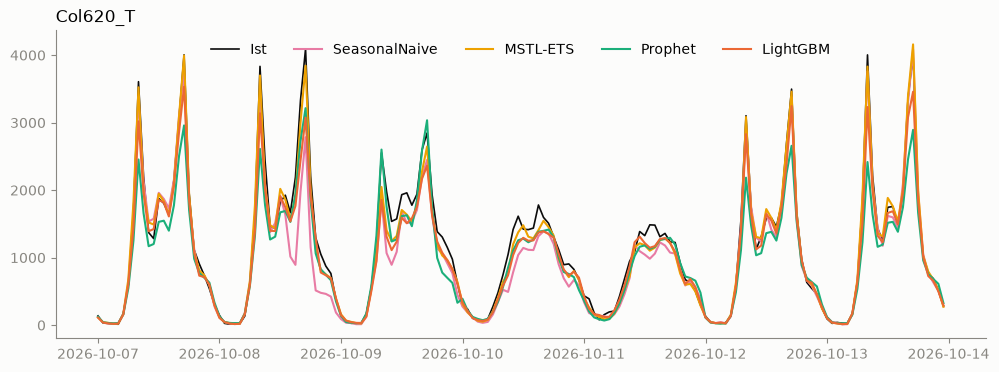

In [5]:
sensor = fc.unique_id.astype(str).mode()[0]
origin = fc.origin.unique()[-4]
week = fc[(fc.unique_id == sensor) & (fc.origin == origin) & (fc.horizon == 168)]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week.drop_duplicates('ds').set_index('ds').y, color=INK, linewidth=1.2, label='Ist')
for m in classic:
    ax.plot(week[week.model == m].set_index('ds').yhat, color=COLORS[m], linewidth=1.5, label=m)
ax.legend(frameon=False, ncol=5)
ax.set_title(f'{sensor}', loc='left');